# Weather analysis
Live data from Open-Meteo, processed with the `weather` package.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
from weather import pipeline
from weather.processing import top_n, filter_range, rankings
from weather.plots import bar_chart
%matplotlib inline

## 1. Fetch + process (default 10 cities)

In [2]:
df = pipeline.run()
df

,City,Latitude,Longitude,Temperature (C),Temperature (F),Humidity (%),Wind Speed (m/s),Wind Speed (mph),Observed At (UTC),Temperature Rank
0,Mumbai,19.0760,72.8777,27.1,80.8,46,2.7,6.1,2026-11-23T20:15,1
1,Rio de Janeiro,-22.9068,-43.1729,27.0,80.6,87,3.5,7.8,2026-11-23T20:15,2
2,Sydney,-33.8688,151.2093,20.6,69.1,80,5.2,11.5,2026-11-23T20:15,3
3,New York,40.7128,-74.0060,20.1,68.2,51,4.6,10.4,2026-11-23T20:15,4
4,Cape Town,-33.9249,18.4241,17.0,62.6,70,4.6,10.2,2026-11-23T20:15,5
5,Tokyo,35.6895,139.6917,11.2,52.2,72,2.7,6.0,2026-11-23T20:15,6
6,London,51.5074,-0.1278,4.3,39.7,72,3.1,6.9,2026-11-23T20:15,7
7,Paris,48.8566,2.3522,4.3,39.7,81,1.9,4.3,2026-11-23T20:15,7
8,Berlin,52.5200,13.4050,1.1,34.0,81,4.0,8.9,2026-11-23T20:15,9
9,Moscow,55.7558,37.6173,0.1,32.2,94,1.0,2.3,2026-11-23T20:15,10


## 2. Rankings and filters

In [3]:
rankings(df)

{'hottest': {'city': 'Mumbai', 'value': 27.1, 'metric': 'Temperature (C)'},
 'coldest': {'city': 'Moscow', 'value': 0.1, 'metric': 'Temperature (C)'},
 'most_humid': {'city': 'Moscow', 'value': 94, 'metric': 'Humidity (%)'},
 'driest': {'city': 'Mumbai', 'value': 46, 'metric': 'Humidity (%)'},
 'windiest': {'city': 'Sydney', 'value': 5.2, 'metric': 'Wind Speed (m/s)'}}

In [4]:
top_n(df, "Humidity (%)", n=3, ascending=True)[["City", "Humidity (%)"]]

,City,Humidity (%)
0,Mumbai,46
3,New York,51
4,Cape Town,70


In [5]:
filter_range(df, "Temperature (C)", min_value=15)[["City", "Temperature (C)", "Temperature (F)"]]

,City,Temperature (C),Temperature (F)
0,Mumbai,27.1,80.8
1,Rio de Janeiro,27.0,80.6
2,Sydney,20.6,69.1
3,New York,20.1,68.2
4,Cape Town,17.0,62.6


## 3. Charts

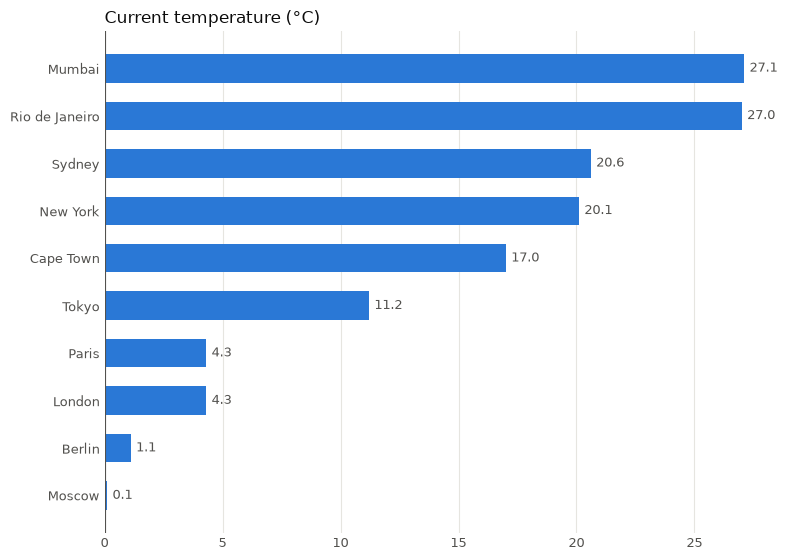

In [6]:
bar_chart(df, "temperature");

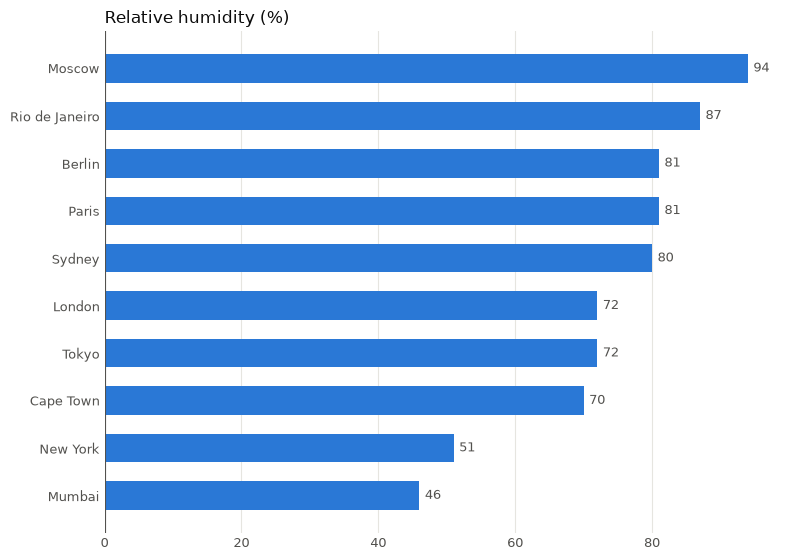

In [7]:
bar_chart(df, "humidity");

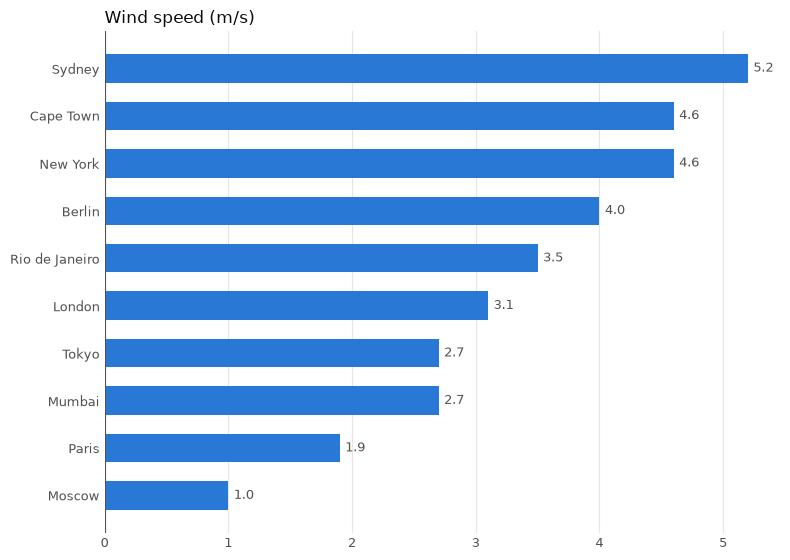

In [8]:
bar_chart(df, "wind");

## 4. Bonus: geocoded cities

In [9]:
pipeline.run(["Lisbon", "Buenos Aires", "Nairobi"])[["City", "Latitude", "Longitude", "Temperature (C)"]]

,City,Latitude,Longitude,Temperature (C)
0,Buenos Aires,-34.6132,-58.3772,28.3
1,Nairobi,-1.2833,36.8167,17.0
2,Lisbon,38.7251,-9.1498,12.7
